# Modelagem preditiva

Nesta etapa, serão desenvolvidos modelos de classificação para prever o churn dos clientes.

A variável-alvo é `churn`, que indica se um cliente cancelou o serviço. O objetivo é identificar padrões associados ao cancelamento e avaliar a capacidade preditiva dos modelos.



## Importando as bibliotecas

In [2]:
import sys

sys.path.append("..")

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from src.cleaning import clean_data
from src.pipeline import BINARY_FEATURES, CATEGORICAL_FEATURES, create_preprocessor


## Carregando a base e separando em treino e teste

In [3]:
df = clean_data(pd.read_csv("../data/raw/Telco-Customer-Churn.csv"))  

X = df.drop(columns=["churn", "customer_id"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean())  

(5634, 19) (1409, 19)
0.2653532126375577


## Validação Cruzada

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["recall", "precision", "f1", "roc_auc"]

def avaliar(nome, modelo, scale, cat_features=None, bin_features=None):
    pipe = Pipeline([
        ("preprocessor", create_preprocessor(scale, cat_features, bin_features)),
        ("classifier", modelo),
    ])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    out = {"modelo": nome, **{m: r[f"test_{m}"].mean() for m in scoring}}
    out["roc_auc_std"] = r["test_roc_auc"].std()
    return out

## Modelos

In [5]:
peso = (y_train == 0).sum() / (y_train == 1).sum()  # ~2.8, calculado só no treino

modelos = {
    "dummy": (DummyClassifier(strategy="most_frequent"), False),
    "logreg": (LogisticRegression(max_iter=1000), True),
    "logreg_balanced": (LogisticRegression(max_iter=1000, class_weight="balanced"), True),
    "tree": (DecisionTreeClassifier(max_depth=5, random_state=42), False),
    "tree_balanced": (DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42), False),
    "rf": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), False),
    "rf_balanced": (RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1), False),
    "xgb": (XGBClassifier(eval_metric="logloss", random_state=42), False),
    "xgb_balanced": (XGBClassifier(eval_metric="logloss", scale_pos_weight=peso, random_state=42), False),
}

## Resultados

In [7]:
resultados = pd.DataFrame(
    [avaliar(nome, m, scale) for nome, (m, scale) in modelos.items()]
).sort_values("roc_auc", ascending=False).round(3)

resultados

c:\Users\Marcos Vinicius\Desktop\Backup Marcos\Marcos\Livros do Marcos\Projetos_DS\Customer_Churn_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Marcos Vinicius\Desktop\Backup Marcos\Marcos\Livros do Marcos\Projetos_DS\Customer_Churn_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Marcos Vinicius\Desktop\Backup Marcos\Marcos\Livros do Marcos\Projetos_DS\Customer_Churn_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetri

,modelo,recall,precision,f1,roc_auc,roc_auc_std
1,logreg,0.543,0.654,0.593,0.846,0.012
2,logreg_balanced,0.803,0.518,0.629,0.846,0.012
3,tree,0.540,0.618,0.574,0.829,0.011
6,rf_balanced,0.654,0.572,0.610,0.828,0.011
4,tree_balanced,0.791,0.498,0.611,0.828,0.013
5,rf,0.491,0.637,0.554,0.826,0.012
7,xgb,0.519,0.621,0.565,0.823,0.007
8,xgb_balanced,0.658,0.551,0.600,0.823,0.008
0,dummy,0.000,0.000,0.000,0.500,0.000


A regressão logística com ponderação das classes (class_weight="balanced") apresentou o melhor desempenho geral entre os modelos avaliados, considerando principalmente o recall e o F1-score médios na validação cruzada.

O modelo obteve recall de 0,803, precision de 0,518, F1-score de 0,629 e ROC-AUC de 0,846. O recall indica maior capacidade de identificar clientes que efetivamente cancelam, embora isso ocorra em conjunto com uma redução da precision e, consequentemente, com a presença de mais falsos positivos.

Além do desempenho observado, a regressão logística oferece uma estrutura relativamente simples e interpretável, favorecendo sua utilização nas próximas etapas do projeto.

Dessa forma, a regressão logística balanceada será selecionada para a avaliação final no conjunto de teste. 

## Testando o modelo com a remoção de algumas variáveis

Na EDA vimos que algumas variáveis possuem uma associação quase nula com churn, aqui vamos observar a performance do modelo sem elas.

In [8]:
baixo_v = ["phone_service", "multiple_lines", "streaming_tv", "streaming_movies"]
cat_sem_gender = [c for c in CATEGORICAL_FEATURES if c != "gender"]
bin_sem_baixo_v = [c for c in BINARY_FEATURES if c not in baixo_v]

modelo = LogisticRegression(max_iter=1000, class_weight="balanced")

pd.DataFrame([
    avaliar("todas", modelo, True),
    avaliar("sem_gender", modelo, True, cat_sem_gender),
    avaliar("sem_5_baixo_V", modelo, True, cat_sem_gender, bin_sem_baixo_v),
]).round(3)

,modelo,recall,precision,f1,roc_auc,roc_auc_std
0,todas,0.803,0.518,0.629,0.846,0.012
1,sem_gender,0.804,0.519,0.631,0.846,0.012
2,sem_5_baixo_V,0.800,0.510,0.623,0.844,0.012


Comparei três conjuntos de variáveis com regressão logística balanceada: todas, sem gender e sem as cinco variáveis com V de Cramér < 0,04. As diferenças ficaram dentro do ruído da validação cruzada (ROC-AUC entre 0,844 e 0,846, desvio de 0,012). A remoção das cinco variáveis piorou levemente todas as métricas, então mantive as binárias e removi apenas gender, que não contribui e não tem relevância para o negócio.

## Ajuste de hiperparâmetros do modelo 

In [9]:
cat_final = cat_sem_gender
bin_final = BINARY_FEATURES

pipe = Pipeline([
    ("preprocessor", create_preprocessor(True, cat_final, bin_final)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

grid = GridSearchCV(
    pipe,
    param_grid={"classifier__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    cv=cv,
    scoring=scoring,
    refit="roc_auc",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Melhor C:", grid.best_params_)
pd.DataFrame(grid.cv_results_)[
    ["param_classifier__C", "mean_test_recall", "mean_test_precision",
     "mean_test_f1", "mean_test_roc_auc"]
].round(3)

Melhor C: {'classifier__C': 10}


,param_classifier__C,mean_test_recall,mean_test_precision,mean_test_f1,mean_test_roc_auc
0,0.01,0.789,0.527,0.632,0.843
1,0.03,0.796,0.522,0.630,0.845
2,0.10,0.800,0.521,0.631,0.846
3,0.30,0.803,0.520,0.631,0.846
4,1.00,0.804,0.519,0.631,0.846
5,3.00,0.803,0.518,0.629,0.846
6,10.00,0.801,0.517,0.628,0.846


Foi realizada uma busca em grade (GridSearchCV) para avaliar diferentes valores do parâmetro C da regressão logística balanceada, utilizando validação cruzada estratificada de cinco folds e ROC-AUC como critério de seleção.

Os resultados apresentaram pouca variação entre os valores testados. O ROC-AUC médio permaneceu em aproximadamente 0,846 para valores de C entre 0,1 e 10, indicando que o desempenho do modelo foi pouco sensível a esse hiperparâmetro na faixa investigada.

Embora a busca tenha selecionado C=10 pelo ROC-AUC médio não arredondado, não foi observado um ganho relevante em relação aos valores menores. Por isso, optou-se por manter C=1, valor padrão da regressão logística, como uma escolha simples e adequada diante da ausência de melhoria expressiva.

## Avaliação do modelo

              precision    recall  f1-score   support

       ficou       0.90      0.72      0.80      1035
       churn       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842


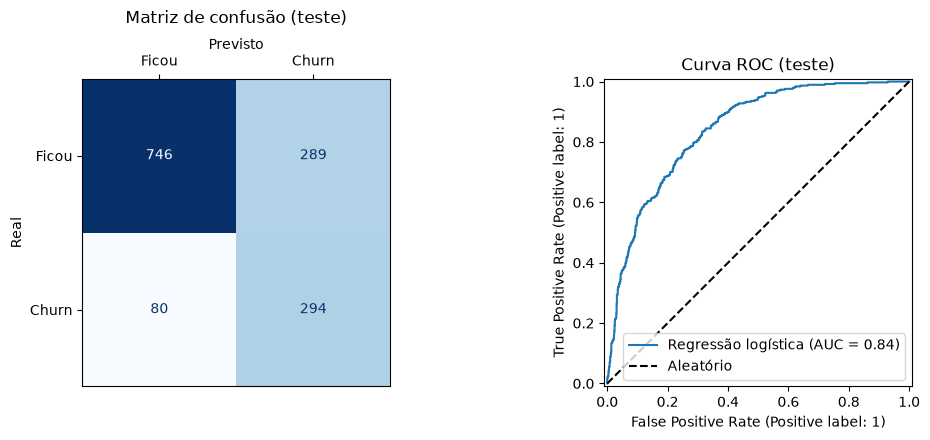

In [16]:

modelo_final = pipe.set_params(classifier__C=1).fit(X_train, y_train)

y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["ficou", "churn"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Ficou", "Churn"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[0],
)
axes[0].xaxis.set_label_position("top")
axes[0].xaxis.tick_top()
axes[0].set_xlabel("Previsto")
axes[0].set_ylabel("Real")
axes[0].set_title("Matriz de confusão (teste)", pad=40)

RocCurveDisplay.from_predictions(
    y_test, y_proba, ax=axes[1], name="Regressão logística"
)
axes[1].plot([0, 1], [0, 1], "k--", label="Aleatório")
axes[1].legend(loc="lower right")
axes[1].set_title("Curva ROC (teste)")

plt.tight_layout()

No conjunto de teste, composto por 1.409 clientes que não participaram do treinamento do modelo, a regressão logística balanceada obteve ROC-AUC de 0.842, recall de 0.79 e precision de 0.50 para a classe churn. O F1-score dessa classe foi de 0.61, enquanto a acurácia geral foi de 0.74.

Os resultados ficaram próximos aos observados na validação cruzada, sugerindo que o desempenho do modelo foi preservado em dados não utilizados durante seu desenvolvimento. O recall indica que o modelo identificou aproximadamente 79% dos clientes que cancelaram, enquanto a precision mostra que cerca de metade dos clientes sinalizados realmente apresentou churn.

Embora a acurácia seja próxima à de um classificador que prevê sempre a permanência do cliente, esse classificador não identificaria nenhum cancelamento. Por isso, a avaliação considerou também recall, precision, F1-score e ROC-AUC, métricas mais informativas para compreender o desempenho na identificação de churn.

O modelo demonstra potencial para apoiar a identificação de clientes com maior risco de cancelamento. Entretanto, sua utilização prática dependeria da análise dos custos dos falsos positivos e dos falsos negativos, bem como da definição de um limiar de classificação adequado ao objetivo do negócio.

<Axes: >

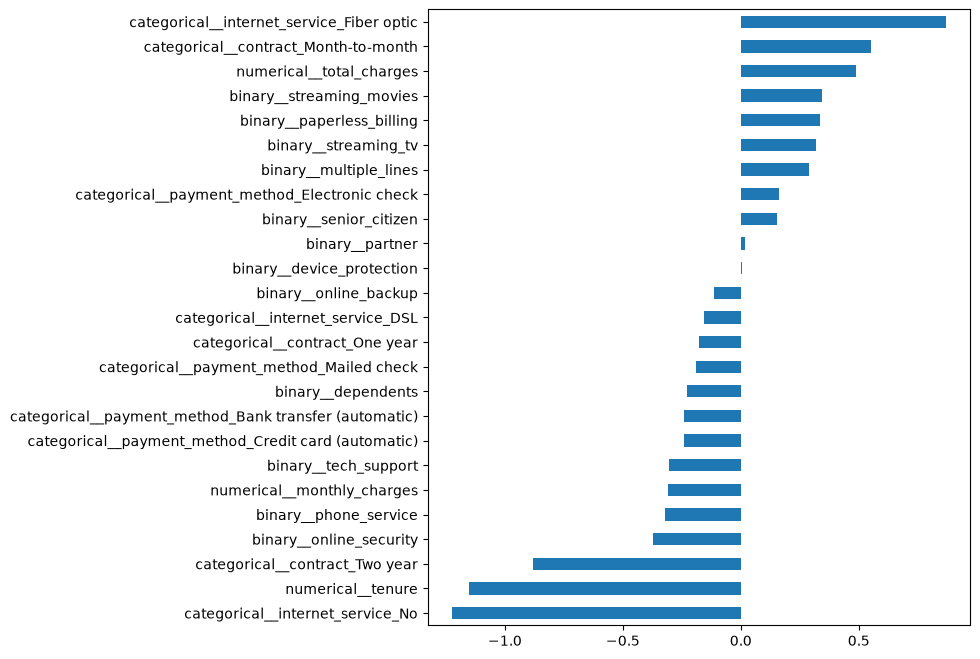

In [14]:
nomes = modelo_final.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(
    modelo_final.named_steps["classifier"].coef_[0], index=nomes
).sort_values()

coefs.plot(kind="barh", figsize=(7, 8))

Os coeficientes da regressão logística indicam que o risco de churn é maior para clientes com contrato mês a mês, pouco tempo de casa, internet de fibra óptica e pagamento por cheque eletrônico. É menor para contratos de dois anos, clientes com suporte técnico e segurança online, e quem não contrata internet. As variáveis tenure, monthly_charges e total_charges são correlacionadas, então seus coeficientes não devem ser interpretados isoladamente. Os resultados descrevem associações, não relações causais.

In [18]:
import numpy as np

odds = np.exp(coefs).sort_values(ascending=False).round(2)
odds

categorical__internet_service_Fiber optic                2.38
categorical__contract_Month-to-month                     1.74
numerical__total_charges                                 1.63
binary__streaming_movies                                 1.41
binary__paperless_billing                                1.40
binary__streaming_tv                                     1.37
binary__multiple_lines                                   1.33
categorical__payment_method_Electronic check             1.18
binary__senior_citizen                                   1.16
binary__partner                                          1.02
binary__device_protection                                1.00
binary__online_backup                                    0.89
categorical__internet_service_DSL                        0.86
categorical__contract_One year                           0.84
categorical__payment_method_Mailed check                 0.83
binary__dependents                                       0.80
categori

Clientes com internet de fibra óptica têm odds ratio de 2,4 para churn, contra 0,86 para DSL e 0,29 para quem não contrata internet. O contrato de dois anos reduz as odds (OR = 0,41), e cada desvio padrão a mais de tempo de casa as reduz em cerca de 68% (OR = 0,32).

## Conclusão

### O que foi feito
Comparei quatro algoritmos (regressão logística, árvore de decisão, Random Forest e XGBoost), cada um em duas versões: sem tratamento do desbalanceamento (cerca de 27% de churn) e com ajuste de pesos das classes. A avaliação usou validação cruzada estratificada de 5 folds apenas no treino, com recall, precisão, F1 e ROC-AUC. O conjunto de teste foi usado uma única vez, no final.

### Modelo escolhido
A regressão logística com `class_weight="balanced"`, sem a variável `gender` e com `C=1`.

- Teve o maior ROC-AUC na validação cruzada (0,846), empatada com a versão sem balanceamento, e superou os modelos de árvore, que ficaram entre 0,823 e 0,829.
- O balanceamento elevou o recall de 0,54 para 0,80 sem perda de ROC-AUC, trocando precisão por recall.
- Remover `gender` e ajustar o `C` não mudou o desempenho além do ruído da validação cruzada (desvio de 0,012), então escolhi a versão mais simples.
- É um modelo interpretável, o que permite explicar os fatores de churn.

### Desempenho no teste
| Métrica | Valor |
|---|---|
| ROC-AUC | 0,842 |
| Recall (churn) | 0,79 |
| Precisão (churn) | 0,50 |
| F1 (churn) | 0,61 |

Os resultados ficaram próximos aos da validação cruzada, indicando boa generalização. O modelo identifica cerca de 8 em cada 10 clientes que cancelam, e cerca de metade dos clientes sinalizados realmente sai, contra 27% na base geral. A acurácia foi próxima à de um classificador que sempre prevê a permanência do cliente, cuja acurácia seria de aproximadamente 0,735. Entretanto, esse classificador não identificaria nenhum cancelamento. Por isso, recall, precisão, F1-score e ROC-AUC foram considerados métricas mais informativas para a seleção e avaliação do modelo.

### O que mais se associa ao churn
- **Contrato:** mês a mês aumenta as odds de churn (OR = 1,74), e o contrato de dois anos as reduz (OR = 0,41).
- **Tempo de casa:** cada desvio padrão a mais de `tenure` reduz as odds em cerca de 68% (OR = 0,32).
- **Internet:** fibra óptica tem OR = 2,38, contra 0,86 para DSL e 0,29 para quem não contrata internet.
- **Serviços:** suporte técnico e segurança online se associam a menos churn.
- **Pagamento:** cheque eletrônico se associa a mais churn, e pagamento automático, a menos.

Esses fatores sugerem onde concentrar a retenção: clientes novos, com contrato mês a mês e internet de fibra. Se a ação for incentivar a migração para contratos mais longos, isso é uma hipótese a testar, não uma conclusão do modelo.

### Limitações
- Os coeficientes mostram associações, não causas.
- `tenure`, `monthly_charges` e `total_charges` são correlacionadas, então seus coeficientes não devem ser interpretados isoladamente.
- O limiar de decisão é o padrão (0,5), e o `class_weight` desloca as probabilidades previstas. O modelo serve para ordenar e sinalizar clientes, não para estimar probabilidades reais.
- A base é de um único período e não foi validada em dados novos.

### Próximos passos
- Ajustar o limiar de decisão conforme o custo de um falso positivo (abordar quem ficaria) e de um falso negativo (perder quem sairia).
- Testar modelos de árvore com ajuste de hiperparâmetros e criação de novas variáveis.
